Język: [English](examples.en.ipynb) | **Polski**

# Wykład 14 — eksperyment: od accuracy do audytu błędów i interpretowalności

Materiał towarzyszący [`lecture.md`](lecture.md). Pięć eksperymentów: (A) od
accuracy do analizy błędów (Fashion-MNIST, `SmallCNN` z modułu 06); (B)
confidence i kalibracja (ECE); (C) Grad-CAM; (D) weryfikacja przez occlusion
sensitivity; (E) sanity check (losowy reset wag). Wszystko na CPU, dane już
zarejestrowane w `data/registry.yml` (moduł 06).

In [1]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as tvd
import torchvision.transforms as T

torch.manual_seed(0)
torch.set_num_threads(4)
device = torch.device("cpu")
print(f"Uzywane urzadzenie: {device}")

notebook_t0 = time.time()

Uzywane urzadzenie: cpu


## 0. Ręczny przykład: confusion matrix, precision/recall/F1, macro/micro-F1

Ten sam przykład, co w `lecture.md` — 3 klasy, celowo nierównomierne,
accuracy wysoka mimo recall=0 dla klasy mniejszościowej.

In [2]:
y_true = torch.tensor([0] * 10 + [1] * 8 + [2] * 2)
y_pred = torch.tensor([0] * 9 + [1] + [1] * 8 + [0] * 2)
assert len(y_true) == len(y_pred) == 20

C = 3
confusion = torch.zeros(C, C, dtype=torch.long)
for t, p in zip(y_true.tolist(), y_pred.tolist()):
    confusion[t, p] += 1
print("confusion matrix (rows=true, cols=pred):")
print(confusion)

accuracy = (y_true == y_pred).float().mean().item()
print(f"\naccuracy = {accuracy:.4f}")
assert abs(accuracy - 17 / 20) < 1e-6

precisions, recalls, f1s = [], [], []
for c in range(C):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp
    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)
    print(f"class {c}: TP={tp} FP={fp} FN={fn} "
          f"precision={precision:.4f} recall={recall:.4f} f1={f1:.4f}")

macro_f1 = sum(f1s) / C
total_tp = sum(confusion[c, c].item() for c in range(C))
micro_f1 = total_tp / len(y_true)
supports = [confusion[c, :].sum().item() for c in range(C)]
weighted_f1 = sum(f1s[c] * supports[c] for c in range(C)) / sum(supports)

print(f"\nmacro-F1 = {macro_f1:.4f}")
print(f"micro-F1 = {micro_f1:.4f} (== accuracy for single-label multi-class)")
print(f"weighted-F1 = {weighted_f1:.4f}")
assert abs(micro_f1 - accuracy) < 1e-6
assert recalls[2] == 0.0
print("\n-> accuracy=0.85 coexists with recall=0 for the minority class -- macro-F1 reveals this.")

confusion matrix (rows=true, cols=pred):
tensor([[9, 1, 0],
        [0, 8, 0],
        [2, 0, 0]])

accuracy = 0.8500
class 0: TP=9 FP=2 FN=1 precision=0.8182 recall=0.9000 f1=0.8571
class 1: TP=8 FP=1 FN=0 precision=0.8889 recall=1.0000 f1=0.9412
class 2: TP=0 FP=0 FN=2 precision=nan recall=0.0000 f1=0.0000

macro-F1 = 0.5994
micro-F1 = 0.8500 (== accuracy for single-label multi-class)
weighted-F1 = 0.8050

-> accuracy=0.85 coexists with recall=0 for the minority class -- macro-F1 reveals this.


## 0.1. Ręczny przykład: ECE

In [3]:
confidences_demo = torch.tensor([0.95, 0.95, 0.95, 0.95, 0.55, 0.55, 0.55, 0.55, 0.55, 0.55])
correct_demo = torch.tensor([1, 1, 1, 0, 1, 1, 0, 0, 0, 0], dtype=torch.float)


def compute_ece(confidences, correct, n_bins=10):
    bin_edges = torch.linspace(0, 1, n_bins + 1)
    n = len(confidences)
    ece = 0.0
    bin_stats = []
    for m in range(n_bins):
        lo, hi = bin_edges[m], bin_edges[m + 1]
        mask = (confidences >= lo) & (confidences < hi) if m < n_bins - 1 \
            else (confidences >= lo) & (confidences <= hi)
        n_m = mask.sum().item()
        if n_m == 0:
            continue
        acc_m = correct[mask].float().mean().item()
        conf_m = confidences[mask].mean().item()
        ece += (n_m / n) * abs(acc_m - conf_m)
        bin_stats.append((lo.item(), hi.item(), n_m, acc_m, conf_m))
    return ece, bin_stats


ece_demo, bin_stats_demo = compute_ece(confidences_demo, correct_demo, n_bins=10)
print(f"ECE = {ece_demo:.4f} (expected: 0.21)")
for lo, hi, n_m, acc_m, conf_m in bin_stats_demo:
    print(f"  [{lo:.1f},{hi:.1f}): n={n_m}, acc={acc_m:.4f}, conf={conf_m:.4f}")
assert abs(ece_demo - 0.21) < 1e-6

ECE = 0.2100 (expected: 0.21)
  [0.5,0.6): n=6, acc=0.3333, conf=0.5500
  [0.9,1.0): n=4, acc=0.7500, conf=0.9500


In [4]:
# ECE sensitivity to bin count and sample size -- measured, not just claimed
torch.manual_seed(0)
n_syn = 200
conf_syn = torch.rand(n_syn) * 0.5 + 0.5
correct_syn = (torch.rand(n_syn) < (conf_syn - 0.15)).float()

print("ECE vs number of bins (same data):")
for nb in [5, 10, 15, 20, 50]:
    ece_nb, _ = compute_ece(conf_syn, correct_syn, n_bins=nb)
    print(f"  n_bins={nb}: ECE={ece_nb:.4f}")

print("\nECE vs sample size (same n_bins=10):")
for sub_n in [20, 50, 100, 200]:
    torch.manual_seed(1)
    idx = torch.randperm(n_syn)[:sub_n]
    ece_sub, _ = compute_ece(conf_syn[idx], correct_syn[idx], n_bins=10)
    print(f"  n={sub_n}: ECE={ece_sub:.4f}")

ECE vs number of bins (same data):
  n_bins=5: ECE=0.1569
  n_bins=10: ECE=0.1569
  n_bins=15: ECE=0.1569
  n_bins=20: ECE=0.1569
  n_bins=50: ECE=0.1746

ECE vs sample size (same n_bins=10):
  n=20: ECE=0.1929
  n=50: ECE=0.1642
  n=100: ECE=0.1181
  n=200: ECE=0.1569


## A. Od accuracy do analizy błędów (Fashion-MNIST, `SmallCNN`)

`SmallCNN` z modułu 06, wytrenowany od zera w tym notebooku (nie z
prywatnego checkpointu). **Poprawka architektury**: osobne instancje
`relu1`/`relu2`/`pool1`/`pool2` (moduł 06 używał jednej współdzielonej
instancji `ReLU`/`MaxPool2d` dla obu warstw -- niewidoczne dla zwykłego
treningu, ale **łamie** hook-based Grad-CAM, patrz Eksperyment C).

In [5]:
t0 = time.time()
train_full = tvd.FashionMNIST(root="data_cache", train=True, download=True, transform=T.ToTensor())
test_full = tvd.FashionMNIST(root="data_cache", train=False, download=True, transform=T.ToTensor())
print(f"load time: {time.time() - t0:.2f}s")

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

N_TRAIN, N_TEST = 8000, 2000
X_train = torch.stack([train_full[i][0] for i in range(N_TRAIN)])
y_train = torch.tensor([train_full[i][1] for i in range(N_TRAIN)])
X_test = torch.stack([test_full[i][0] for i in range(N_TEST)])
y_test = torch.tensor([test_full[i][1] for i in range(N_TEST)])
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

load time: 0.02s


X_train: torch.Size([8000, 1, 28, 28]), X_test: torch.Size([2000, 1, 28, 28])


In [6]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.flatten(1)
        return self.fc(x)


torch.manual_seed(0)
model = SmallCNN()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

t0 = time.time()
for epoch in range(10):
    perm = torch.randperm(N_TRAIN)
    for i in range(0, N_TRAIN, 64):
        idx = perm[i:i + 64]
        opt.zero_grad()
        out = model(X_train[idx])
        loss = loss_fn(out, y_train[idx])
        loss.backward()
        opt.step()
train_time = time.time() - t0
print(f"train_time (10 epochs): {train_time:.2f}s")

train_time (10 epochs): 7.96s


eval_time: 0.07s, test_acc: 0.8745


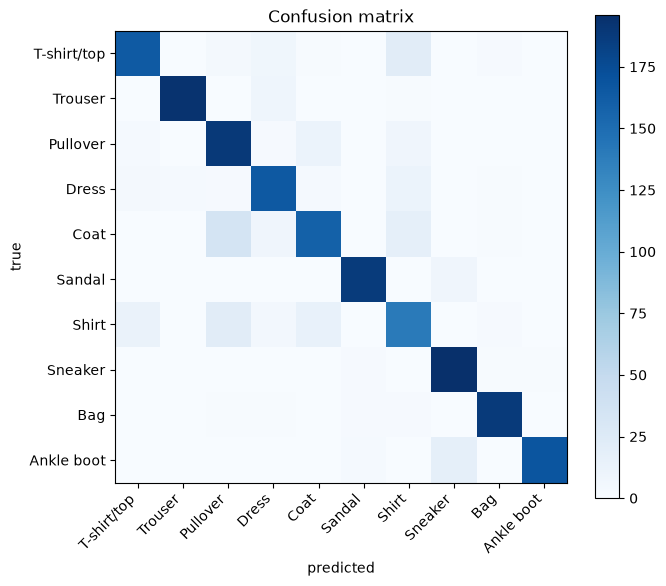

In [7]:
model.eval()
t0 = time.time()
with torch.no_grad():
    test_logits = model(X_test)
eval_time = time.time() - t0
test_probs = F.softmax(test_logits, dim=1)
test_pred = test_logits.argmax(1)
test_acc = (test_pred == y_test).float().mean().item()
print(f"eval_time: {eval_time:.2f}s, test_acc: {test_acc:.4f}")

C = 10
confusion = torch.zeros(C, C, dtype=torch.long)
for t, p in zip(y_test.tolist(), test_pred.tolist()):
    confusion[t, p] += 1

plt.figure(figsize=(7, 6))
plt.imshow(confusion.numpy(), cmap="Blues")
plt.xticks(range(C), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(C), CLASS_NAMES)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("Confusion matrix")
plt.colorbar()
plt.tight_layout()
plt.show()

In [8]:
precisions, recalls, f1s = [], [], []
for c in range(C):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp
    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)
    print(f"{CLASS_NAMES[c]:14s}: P={precision:.3f} R={recall:.3f} F1={f1:.3f}")

macro_f1 = sum(f1s) / C
print(f"\nmacro-F1 = {macro_f1:.4f}, accuracy(micro-F1) = {test_acc:.4f}")

conf_no_diag = confusion.clone().float()
conf_no_diag.fill_diagonal_(0)
max_idx = conf_no_diag.argmax()
i, j = max_idx.item() // C, max_idx.item() % C
print(f"\nmost confused pair: true={CLASS_NAMES[i]} predicted={CLASS_NAMES[j]}, "
      f"count={conf_no_diag[i, j].item():.0f}")
conf_no_diag[i, j] = 0
max_idx2 = conf_no_diag.argmax()
i2, j2 = max_idx2.item() // C, max_idx2.item() % C
print(f"2nd most confused pair: true={CLASS_NAMES[i2]} predicted={CLASS_NAMES[j2]}, "
      f"count={conf_no_diag[i2, j2].item():.0f}")

T-shirt/top   : P=0.891 R=0.820 F1=0.854
Trouser       : P=0.985 R=0.951 F1=0.967
Pullover      : P=0.750 R=0.883 F1=0.811
Dress         : P=0.838 R=0.868 F1=0.853
Coat          : P=0.837 R=0.726 F1=0.778
Sandal        : P=0.964 R=0.959 F1=0.961
Shirt         : P=0.693 R=0.711 F1=0.702
Sneaker       : P=0.887 R=0.980 F1=0.931
Bag           : P=0.964 R=0.969 F1=0.967
Ankle boot    : P=0.994 R=0.894 F1=0.941

macro-F1 = 0.8765, accuracy(micro-F1) = 0.8745

most confused pair: true=Coat predicted=Pullover, count=34
2nd most confused pair: true=T-shirt/top predicted=Shirt, count=22


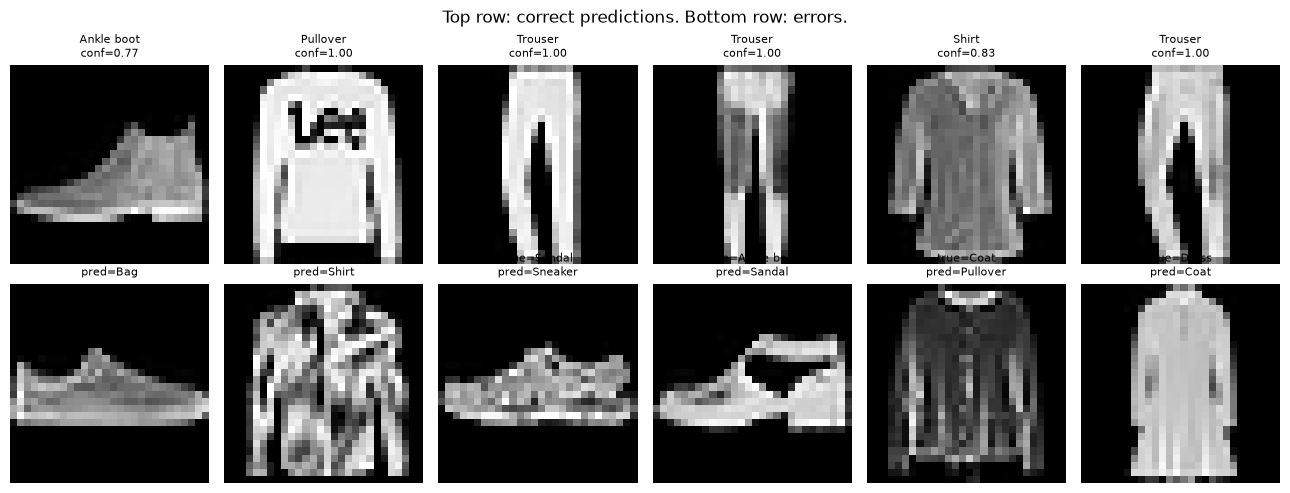

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
correct_mask = test_pred == y_test
correct_examples = correct_mask.nonzero(as_tuple=True)[0][:6]
wrong_examples = (~correct_mask).nonzero(as_tuple=True)[0][:6]
for col, idx in enumerate(correct_examples.tolist()):
    axes[0, col].imshow(X_test[idx, 0], cmap="gray")
    conf_i = test_probs[idx, test_pred[idx]].item()
    axes[0, col].set_title(f"{CLASS_NAMES[test_pred[idx]]}\nconf={conf_i:.2f}", fontsize=8)
    axes[0, col].axis("off")
for col, idx in enumerate(wrong_examples.tolist()):
    axes[1, col].imshow(X_test[idx, 0], cmap="gray")
    axes[1, col].set_title(f"true={CLASS_NAMES[y_test[idx]]}\npred={CLASS_NAMES[test_pred[idx]]}",
                            fontsize=8)
    axes[1, col].axis("off")
fig.suptitle("Top row: correct predictions. Bottom row: errors.")
plt.tight_layout()
plt.show()

## B. Confidence i kalibracja

mean confidence (correct): 0.9082
mean confidence (incorrect): 0.6517


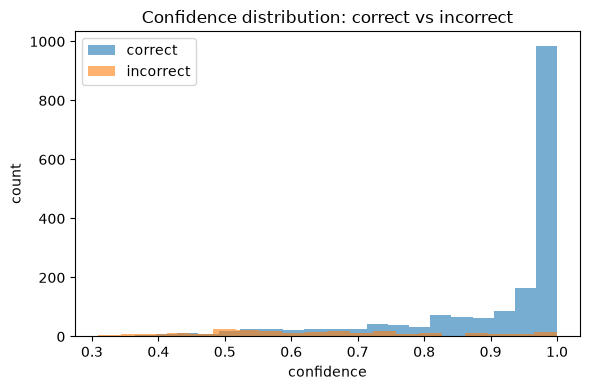

In [10]:
confidences = test_probs.max(dim=1).values
print(f"mean confidence (correct): {confidences[correct_mask].mean().item():.4f}")
print(f"mean confidence (incorrect): {confidences[~correct_mask].mean().item():.4f}")

plt.figure(figsize=(6, 4))
plt.hist(confidences[correct_mask].numpy(), bins=20, alpha=0.6, label="correct")
plt.hist(confidences[~correct_mask].numpy(), bins=20, alpha=0.6, label="incorrect")
plt.xlabel("confidence")
plt.ylabel("count")
plt.legend()
plt.title("Confidence distribution: correct vs incorrect")
plt.tight_layout()
plt.show()

ECE = 0.0099
  [0.3,0.4): n=24, acc=0.375, conf=0.369
  [0.4,0.5): n=73, acc=0.411, conf=0.458
  [0.5,0.6): n=123, acc=0.569, conf=0.550
  [0.6,0.7): n=121, acc=0.636, conf=0.650
  [0.7,0.8): n=160, acc=0.750, conf=0.749
  [0.8,0.9): n=220, acc=0.877, conf=0.851
  [0.9,1.0): n=1279, acc=0.977, conf=0.982


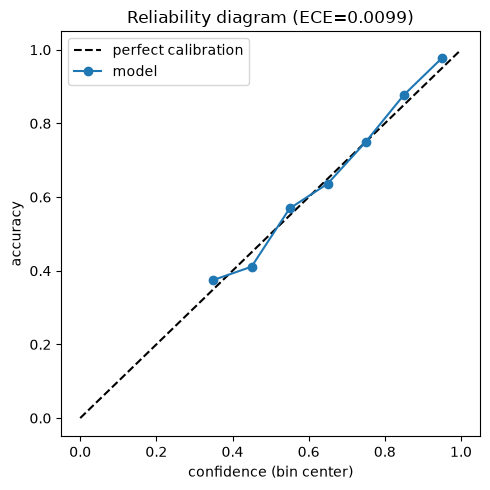

In [11]:
ece, bin_stats = compute_ece(confidences, correct_mask.float())
print(f"ECE = {ece:.4f}")
for lo, hi, n_m, acc_m, conf_m in bin_stats:
    print(f"  [{lo:.1f},{hi:.1f}): n={n_m}, acc={acc_m:.3f}, conf={conf_m:.3f}")

bin_centers = [(lo + hi) / 2 for lo, hi, *_ in bin_stats]
bin_accs = [s[3] for s in bin_stats]
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="perfect calibration")
plt.plot(bin_centers, bin_accs, marker="o", label="model")
plt.xlabel("confidence (bin center)")
plt.ylabel("accuracy")
plt.title(f"Reliability diagram (ECE={ece:.4f})")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
wrong_conf = confidences[~correct_mask]
print(f"max confidence among WRONG predictions: {wrong_conf.max().item():.4f}")
n_high_conf_wrong = ((~correct_mask) & (confidences > 0.9)).sum().item()
print(f"number of wrong predictions with confidence > 0.9: {n_high_conf_wrong}")
if ece < 0.05:
    print(f"\nECE={ece:.4f} is LOW -- this model IS well-calibrated. Writing this "
          f"directly, not forcing an overconfidence narrative the data doesn't show.")

max confidence among WRONG predictions: 0.9996
number of wrong predictions with confidence > 0.9: 29

ECE=0.0099 is LOW -- this model IS well-calibrated. Writing this directly, not forcing an overconfidence narrative the data doesn't show.


## C. Grad-CAM

In [13]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.fwd_handle = target_layer.register_forward_hook(self._save_activation)
        self.bwd_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def __call__(self, x, target_class):
        self.model.zero_grad()
        logits = self.model(x)
        if isinstance(target_class, int):
            target_class = torch.full((x.shape[0],), target_class, dtype=torch.long)
        score = logits.gather(1, target_class.unsqueeze(1)).sum()
        score.backward()

        alpha = self.gradients.mean(dim=(2, 3))
        weighted = (alpha.unsqueeze(-1).unsqueeze(-1) * self.activations).sum(dim=1)
        cam = torch.relu(weighted)
        cam_up = F.interpolate(
            cam.unsqueeze(1), size=x.shape[-2:], mode="bilinear", align_corners=False
        )
        out = torch.empty_like(cam_up)
        for i in range(cam_up.shape[0]):
            cmin, cmax = cam_up[i].min(), cam_up[i].max()
            out[i] = (cam_up[i] - cmin) / (cmax - cmin) if (cmax - cmin).item() > 1e-8 \
                else torch.zeros_like(cam_up[i])
        return out.detach(), logits.detach()

    def remove_hooks(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

In [14]:
# scan for how often the CAM degenerates to all-zero for relu2 (32 channels)
gradcam_scan = GradCAM(model, model.relu2)
n_zero, n_checked = 0, 100
non_degenerate_idx = []
for idx in range(n_checked):
    cam_i, _ = gradcam_scan(X_test[idx:idx + 1], target_class=test_pred[idx:idx + 1])
    if (cam_i == 0).all().item():
        n_zero += 1
    else:
        non_degenerate_idx.append(idx)
gradcam_scan.remove_hooks()
print(f"out of {n_checked} test images, {n_zero} gave an all-zero CAM for their predicted class")
print(f"non-degenerate indices (first 10): {non_degenerate_idx[:10]}")

out of 100 test images, 65 gave an all-zero CAM for their predicted class
non-degenerate indices (first 10): [2, 3, 7, 8, 11, 12, 18, 23, 26, 30]


In [15]:
# select concrete examples: correct / wrong / high-confidence-wrong, all non-degenerate
gradcam_sel = GradCAM(model, model.relu2)

correct_example = next(i for i in non_degenerate_idx if test_pred[i].item() == y_test[i].item())

wrong_example = None
for idx in range(N_TEST):
    if test_pred[idx].item() != y_test[idx].item():
        cam_i, _ = gradcam_sel(X_test[idx:idx + 1], target_class=test_pred[idx:idx + 1])
        if not (cam_i == 0).all().item():
            wrong_example = idx
            break

high_conf_wrong_candidates = [
    i for i in range(N_TEST)
    if test_pred[i].item() != y_test[i].item() and confidences[i].item() > 0.9
]
high_conf_wrong_example = None
for idx in high_conf_wrong_candidates:
    cam_i, _ = gradcam_sel(X_test[idx:idx + 1], target_class=test_pred[idx:idx + 1])
    if not (cam_i == 0).all().item():
        high_conf_wrong_example = idx
        break

gradcam_sel.remove_hooks()
print(f"correct example: idx={correct_example}")
print(f"wrong example: idx={wrong_example}")
print(f"high-confidence wrong example: idx={high_conf_wrong_example}")

correct example: idx=2
wrong example: idx=12
high-confidence wrong example: idx=23


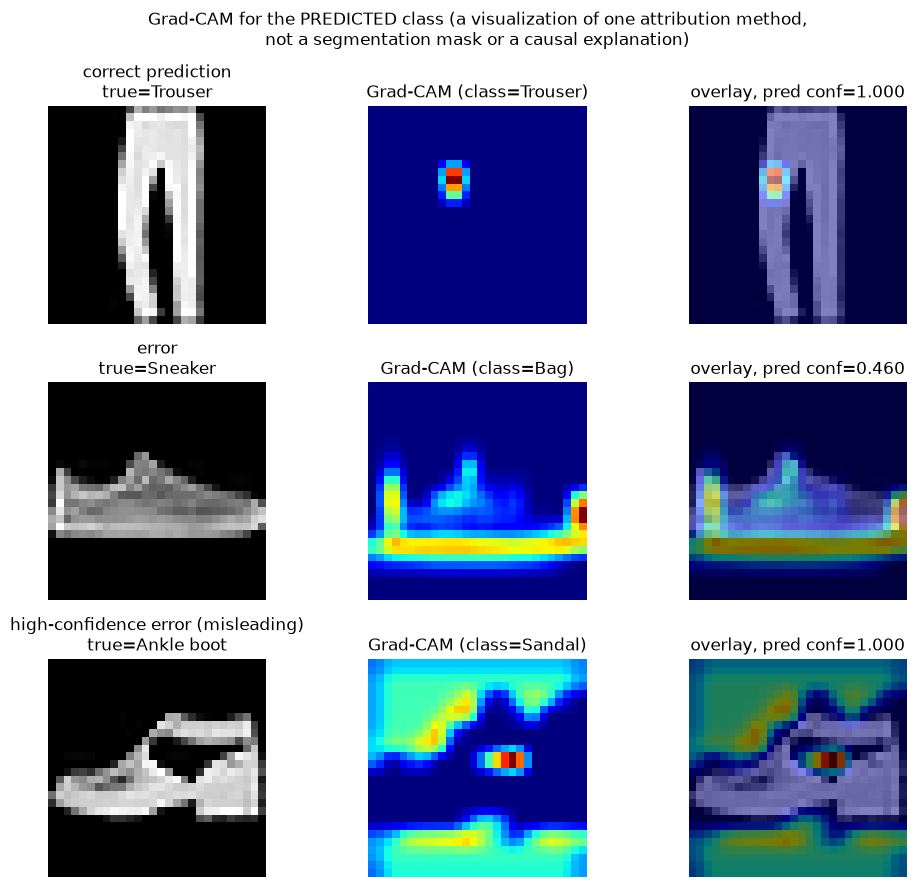

In [16]:
gradcam = GradCAM(model, model.relu2)
examples = [
    ("correct prediction", correct_example),
    ("error", wrong_example),
    ("high-confidence error (misleading)", high_conf_wrong_example),
]

fig, axes = plt.subplots(len(examples), 3, figsize=(10, 9))
for row, (title, idx) in enumerate(examples):
    img = X_test[idx:idx + 1]
    cam_map, logits_i = gradcam(img, target_class=test_pred[idx:idx + 1])
    prob_i = F.softmax(logits_i, dim=1)[0, test_pred[idx]].item()

    axes[row, 0].imshow(img[0, 0], cmap="gray")
    axes[row, 0].set_title(f"{title}\ntrue={CLASS_NAMES[y_test[idx]]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cam_map[0, 0], cmap="jet")
    axes[row, 1].set_title(f"Grad-CAM (class={CLASS_NAMES[test_pred[idx]]})")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(img[0, 0], cmap="gray")
    axes[row, 2].imshow(cam_map[0, 0], cmap="jet", alpha=0.5)
    axes[row, 2].set_title(f"overlay, pred conf={prob_i:.3f}")
    axes[row, 2].axis("off")

fig.suptitle("Grad-CAM for the PREDICTED class (a visualization of one attribution method,\n"
             "not a segmentation mask or a causal explanation)")
plt.tight_layout()
plt.show()
gradcam.remove_hooks()

## D. Weryfikacja przez occlusion sensitivity

In [17]:
def occlusion_sensitivity(model, x, target_class, patch_size=4, stride=4, baseline=0.0):
    model.eval()
    with torch.no_grad():
        base_logit = model(x.unsqueeze(0))[0, target_class].item()
    H, W = x.shape[-2:]
    heatmap = torch.zeros(H, W)
    for i in range(0, H, stride):
        for j in range(0, W, stride):
            x_occ = x.clone()
            x_occ[:, i:i + patch_size, j:j + patch_size] = baseline
            with torch.no_grad():
                occ_logit = model(x_occ.unsqueeze(0))[0, target_class].item()
            heatmap[i:i + patch_size, j:j + patch_size] = base_logit - occ_logit
    return heatmap, base_logit

occlusion_time: 0.007s, base_logit=9.644, heatmap range=[-0.975,5.369]


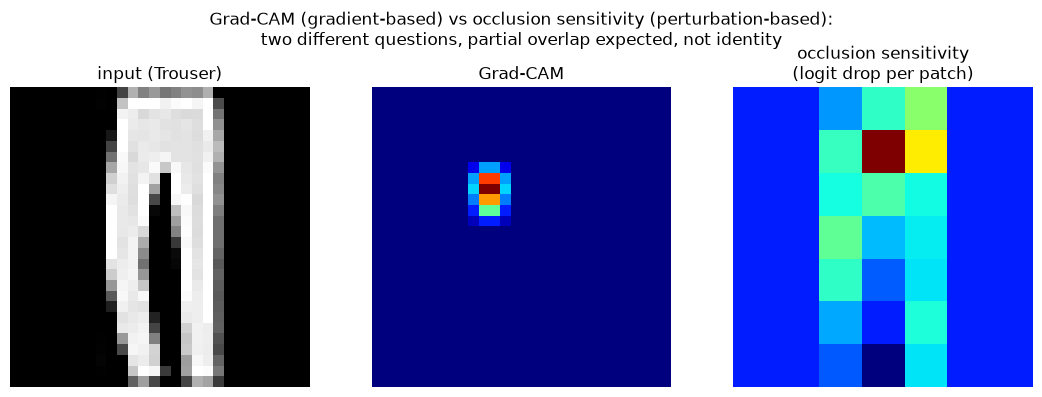


Note: occlusion replaces pixels with baseline=0, which is a NATURAL background value for Fashion-MNIST (ToTensor range [0,1], typically black background) -- a less careful baseline could itself distort the comparison.


In [18]:
gradcam_d = GradCAM(model, model.relu2)
idx = correct_example
img = X_test[idx]
target = test_pred[idx].item()

t0 = time.time()
occ_heatmap, base_logit = occlusion_sensitivity(
    model, img, target, patch_size=4, stride=4, baseline=0.0
)
occ_time = time.time() - t0
cam_map_d, _ = gradcam_d(img.unsqueeze(0), target_class=target)
gradcam_d.remove_hooks()

print(f"occlusion_time: {occ_time:.3f}s, base_logit={base_logit:.3f}, "
      f"heatmap range=[{occ_heatmap.min():.3f},{occ_heatmap.max():.3f}]")

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(img[0], cmap="gray")
axes[0].set_title(f"input ({CLASS_NAMES[target]})")
axes[0].axis("off")
axes[1].imshow(cam_map_d[0, 0], cmap="jet")
axes[1].set_title("Grad-CAM")
axes[1].axis("off")
axes[2].imshow(occ_heatmap, cmap="jet")
axes[2].set_title("occlusion sensitivity\n(logit drop per patch)")
axes[2].axis("off")
fig.suptitle("Grad-CAM (gradient-based) vs occlusion sensitivity (perturbation-based):\n"
             "two different questions, partial overlap expected, not identity")
plt.tight_layout()
plt.show()
print("\nNote: occlusion replaces pixels with baseline=0, which is a NATURAL "
      "background value for Fashion-MNIST (ToTensor range [0,1], typically black "
      "background) -- a less careful baseline could itself distort the comparison.")

## E. Sanity check: wrażliwość Grad-CAM na parametry modelu

cam_before: min=0.0000 max=1.0000
cam_after:  min=0.0000 max=1.0000
mean absolute difference: 0.1384
(correlation would be undefined/NaN whenever either map is degenerate -- mean absolute difference is the more robust default here, a MEASURED choice, not an arbitrary one)


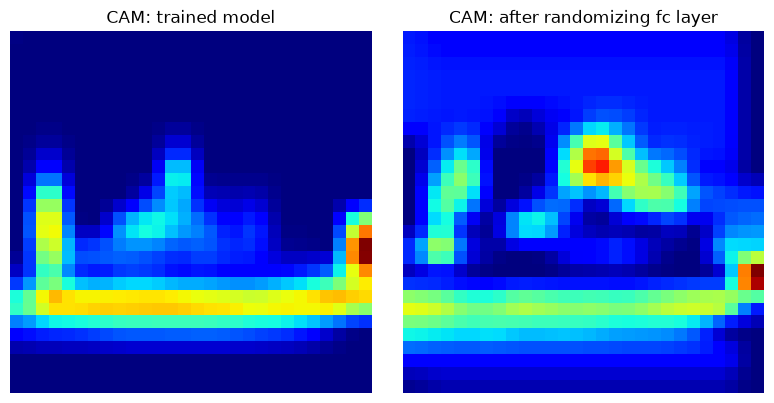

In [19]:
model_randomized = SmallCNN()
model_randomized.load_state_dict(model.state_dict())
model_randomized.eval()
torch.manual_seed(999)
with torch.no_grad():
    model_randomized.fc.weight.normal_(0, 0.1)
    model_randomized.fc.bias.zero_()

gradcam_before = GradCAM(model, model.relu2)
gradcam_after = GradCAM(model_randomized, model_randomized.relu2)

idx = non_degenerate_idx[5]  # pick one with a non-degenerate map for a meaningful comparison
cam_before, _ = gradcam_before(X_test[idx:idx + 1], target_class=test_pred[idx:idx + 1])
cam_after, _ = gradcam_after(X_test[idx:idx + 1], target_class=test_pred[idx:idx + 1])

mad = (cam_before - cam_after).abs().mean().item()
print(f"cam_before: min={cam_before.min():.4f} max={cam_before.max():.4f}")
print(f"cam_after:  min={cam_after.min():.4f} max={cam_after.max():.4f}")
print(f"mean absolute difference: {mad:.4f}")
print("(correlation would be undefined/NaN whenever either map is degenerate -- "
      "mean absolute difference is the more robust default here, a MEASURED choice, "
      "not an arbitrary one)")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(cam_before[0, 0], cmap="jet")
axes[0].set_title("CAM: trained model")
axes[0].axis("off")
axes[1].imshow(cam_after[0, 0], cmap="jet")
axes[1].set_title("CAM: after randomizing fc layer")
axes[1].axis("off")
plt.tight_layout()
plt.show()

gradcam_before.remove_hooks()
gradcam_after.remove_hooks()

## Weryfikacja: `model.eval()` vs `torch.no_grad()` vs `torch.inference_mode()`

In [20]:
model.eval()
x_check = X_test[0:1]

print("=== model.eval() alone: gradients still work ===")
out = model(x_check)
out[0, 0].backward()
print("backward succeeded:", model.conv1.weight.grad is not None)
model.zero_grad()

print("\n=== torch.no_grad(): breaks gradient tracking ===")
try:
    with torch.no_grad():
        out = model(x_check)
        out[0, 0].backward()
except RuntimeError as e:
    print("RuntimeError:", str(e)[:100])

print("\n=== torch.inference_mode(): breaks it too, more strictly ===")
try:
    with torch.inference_mode():
        out = model(x_check)
        out[0, 0].backward()
except RuntimeError as e:
    print("RuntimeError:", str(e)[:100])

with torch.inference_mode():
    out_inf = model(x_check)
try:
    out_inf.requires_grad_(True)
except RuntimeError as e:
    print("RuntimeError (inference tensor outside its context):", str(e)[:120])

=== model.eval() alone: gradients still work ===
backward succeeded: True

=== torch.no_grad(): breaks gradient tracking ===
RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

=== torch.inference_mode(): breaks it too, more strictly ===
RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn
RuntimeError (inference tensor outside its context): Setting requires_grad=True on inference tensor outside InferenceMode is not allowed.


In [21]:
print(f"\ntotal time so far: {time.time() - notebook_t0:.1f}s")


total time so far: 9.0s
